## 1\. Write a function that converts number representation, bin<->dec<->hex. (Clearly using the corresponding python built-in functions is not fair..)

In [21]:
def convert_base(number_str, from_base, to_base): #three inputs, the number string, the origin and the destination base
    
    HEX_CHARS = "0123456789ABCDEF"
    
    # 1. Convert to the initial base to decimal always (Base 10)
    if from_base == 10:
        decimal_val = int(number_str) 
    else:
        decimal_val = 0
        number_str = number_str.upper().strip() # to make sure that there are no spaces or lower letters in the string, avoid errors

        for char in number_str:
            if char not in HEX_CHARS[:from_base]:
                raise ValueError(f"Invalid character '{char}' for the base {from_base}")
            value = HEX_CHARS.index(char)
            decimal_val = decimal_val * from_base + value
            
    # 2. If the input base is decimal we stop here
    if to_base == 10:
        return str(decimal_val)
        
    # 3. Convert from decimal to destiny base (bin or hex)
    if decimal_val == 0:
        return "0"
    result_chars = []
    while decimal_val > 0: #applying the general double-dabble method (in binary we divide by two, in hex by 16)
        remainder = decimal_val % to_base
        result_chars.append(HEX_CHARS[remainder])
        decimal_val = decimal_val // to_base # integer division and round down.
        
    # Invert our result becuase the double-dabble method gives the number inverted. 
    return "".join(result_chars[::-1])



# BIN TO HEX
print(convert_base("11110111", from_base=2, to_base=16))
# HEX TO DEC
print(convert_base("1AF", from_base=16, to_base=10))    
# DEC TO BIN
print(convert_base("42", from_base=10, to_base=2))     



F7
431
101010


## 2\. Write a function that converts a 32 bit word into a single precision floating point (i.e. interprets the various bits as sign, mantissa and exponent)

In [55]:
string = str(input('Type your desired 32 bit binary number to convert to decimal using floatingpoint:'))

#Checking of the 32 bits of the binary number
if len(string) > 32:
    string = string[0:31]
elif len(string) < 32:
    while len(string) <32:
        string = ''.join((string,'0')) #introduce 0 to the back until reaching 32 bits --> WORKS!

bias = 127

def floatingpoint(string, bias):
    sign = int(string[0]) # the first bit of the binary number is our sign
    exponent = string[1:9] # from bit 2 to 9
    exponent_dec = int(exponent, 2)
    print('Exponent in decimal: ', exponent_dec)
    mantissa = string[10:]
    
    decimals = []
    for i in range(len(mantissa)):
        dec = int(mantissa[i]) * 2**(-(i+1))
        decimals.append(dec)
    print('Decimal parts',decimals)
    
    fractional_part = np.sum(decimals)
    print('Mantissa without the 1:', fractional_part)
    result = ((-1)**sign) * (1 + fractional_part) * (2 **(exponent_dec-bias))
    return result

print(string)
floatingpoint(string,bias)

Type your desired 32 bit binary number to convert to decimal using floatingpoint: 011001110101100110


01100111010110011000000000000000
Exponent in decimal:  206
Decimal parts [0.0, 0.25, 0.125, 0.0, 0.0, 0.015625, 0.0078125, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Mantissa without the 1: 0.3984375


np.float64(8.453036004336665e+23)

## 3\. Write a program to determine the underflow and overflow limits (within a factor of 2) for python on your computer. 

**Tips**: define two variables inizialized to 1 and halve/double them enough time to exceed the under/over-flow limits  

In [57]:
# Safer Underflow Loop
underflow = 1.0
last_valid_underflow = underflow
while underflow > 0.0:
    last_valid_underflow = underflow
    underflow /= 2.0

# Safer Overflow Loop (Checks for 'inf' explicitly to avoid freezing)
overflow = 1.0
last_valid_overflow = overflow
while True:
    try:
        next_value = overflow * 2.0
        # If it hits infinity without throwing an error, stop the loop
        if next_value == float('inf'):
            break
        last_valid_overflow = next_value
        overflow = next_value
    except OverflowError:
        break

print(f"Underflow Limit: {last_valid_underflow}")
print(f"Overflow Limit:  {last_valid_overflow}")


Underflow Limit: 5e-324
Overflow Limit:  8.98846567431158e+307


## 4\. Write a program to determine the machine precision

**Tips**: define a new variable by adding a smaller and smaller value (proceeding similarly to prob. 2) to an original variable and check the point where the two are the same 

In [66]:
# Initialize epsilon to 1.0
eps = 1.0
last_valid_eps = eps

# Keep halving eps until adding it to 1.0 makes no difference
while (1.0 + eps) > 1.0:
    last_valid_eps = eps
    eps /= 2.0

print(f"Machine Precision (Epsilon) within a factor of 2: {last_valid_eps}")


Machine Precision (Epsilon) within a factor of 2: 2.220446049250313e-16


## 5\. Write a function that takes in input three parameters $a$, $b$ and $c$ and prints out the two solutions to the quadratic equation $ax^2+bx+c=0$ using the standard formula:
$$
x=\frac{-b\pm\sqrt{b^2-4ac}}{2a}
$$

### (a) use the program to compute the solution for $a=0.001$, $b=1000$ and $c=0.001$

### (b) re-express the standard solution formula by multiplying top and bottom by $-b\mp\sqrt{b^2-4ac}$ and again find the solution for $a=0.001$, $b=1000$ and $c=0.001$. How does it compare with what previously obtained? Why?

### (c) write a function that compute the roots of a quadratic equation accurately in all cases

In [2]:
# (a) 

import numpy as np

def quadratic_formula_standard(a,b,c):
    sq = np.sqrt(b**2 - 4*a*c)
    x1 = (-b + sq) /(2*a)
    x2 = (-b - sq) /(2*a)
    return (x1, x2) # both solutions of the quadratic formula

solution = quadratic_formula_standard(0.001, 1000, 0.001)
print('The solution are:', '\n x1 =', solution[0], '\n x2 = ', solution[1])
    

The solution are: 
 x1 = -9.999894245993346e-07 
 x2 =  -999999.999999


In [3]:
def quadratic_formula_modified(a, b, c):
    sq = np.sqrt(b**2 - 4*a*c)
    x1 = 2*c / (-b - sq)   # equivale a (-b + sq)/(2a)
    x2 = 2*c / (-b + sq)   # equivale a (-b - sq)/(2a)
    return x1, x2

sol = quadratic_formula_modified(0.001, 1000, 0.001)
print('The solutions are:', '\n x1 =', sol[0], '\n x2 =', sol[1])
print('\nCompare standard vs modified:')
print('x1:', solution[0], sol[0])
print('x2:', solution[1], sol[1])


The solutions are: 
 x1 = -1.000000000001e-06 
 x2 = -1000010.5755125057

Compare standard vs modified:
x1: -9.999894245993346e-07 -1.000000000001e-06
x2: -999999.999999 -1000010.5755125057


#### Comparación y por qué. 
Las raíces exactas son aproximadamente x₁ ≈ −1·10⁻⁶ y x₂ ≈ −1·10⁶. Aquí b² ≫ 4ac, así que √(b²−4ac) ≈ b y aparece una cancelación catastrófica:

En la fórmula estándar, x₁ tiene en el numerador −b + √D, la resta de dos números casi iguales (≈1000 y ≈1000). Se pierden casi todos los dígitos significativos y x₁ sale con un error relativo notable (en torno a 10⁻⁵ o peor).
En la fórmula modificada, x₁ = 2c/(−b − √D) suma dos números del mismo signo, así que no hay pérdida de precisión y x₁ es muy preciso. Pero ahora x₂ = 2c/(−b + √D) es la que sufre la cancelación, y es la que sale mal.

Cada fórmula es precisa para una raíz y mala para la otra. La causa no es el almacenamiento, sino restar números casi iguales, que amplifica el error de redondeo de la aritmética de punto flotante.

In [4]:
# (c)
import cmath

def quadratic_roots(a, b, c):
    
    disc = b**2 - 4*a*c
    # Raíz cuadrada real o compleja según el signo del discriminante
    sq = np.sqrt(disc) if disc >= 0 else cmath.sqrt(disc)

    # Elegimos el signo para que b y sgn(b)*sq se SUMEN (sin cancelación)
    sign_b = 1.0 if (np.real(b) >= 0) else -1.0
    q = -0.5 * (b + sign_b * sq)

    x1 = q / a
    x2 = c / q if q != 0 else x1   # q = 0 solo si b = 0 y disc = 0 -> raíz doble 0
    return x1, x2

# Prueba
a, b, c = 0.001, 1000, 0.001
r = quadratic_roots(a, b, c)
print('Roots:', r)
print('Check residuals:', [a*x**2 + b*x + c for x in r])


Roots: (np.float64(-999999.999999), np.float64(-1.000000000001e-06))
Check residuals: [np.float64(7.247924804689582e-08), np.float64(0.0)]


## 6\. Write a program that implements the function $f(x)=x(x−1)$

(a) Calculate the derivative of the function at the point $x = 1$ using the derivative definition:

$$
\frac{{\rm d}f}{{\rm d}x} = \lim_{\delta\to0} \frac{f(x+\delta)-f(x)}{\delta}
$$

with $\delta = 10^{−2}$. Calculate the true value of the same derivative analytically and compare with the answer your program gives. The two will not agree perfectly. Why not?

(b) Repeat the calculation for $\delta = 10^{−4}, 10^{−6}, 10^{−8}, 10^{−10}, 10^{−12}$ and $10^{−14}$. How does the accuracy scales with $\delta$?

In [2]:
# (a) 

import numpy as np
import mpmath as mp #package with computation of the limit

def function(x):
    return x*(x-1)

# The derivative is defined as above
x1 = 1 #point where we want to evaluate the derivative
exp = 2
delta = 10**(-exp)

def df_definition(x, delta): 
    'Derivative by the definition'
    return (function(x+delta)-function(x))/(delta)
    
def df_analytical(x):
    'Derivative analytically computed'
    return 2*x-1 

r = df_definition(x1,delta)
q = df_analytical(x1)

print(f'Result by definition at x = {x1}: ',r, f'\nResult by analytically computing it at x = {x1}: ', q)
print('Relative error between them: ', np.abs((q-r)/r))

Result by definition at x = 1:  1.010000000000001 
Result by analytically computing it at x = 1:  1
Relative error between them:  0.00990099009901078


Result by definition at x = 1 with delta = 0.01:  1.010000000000001 
Result by analytically computing it at x = 1:  1
Relative error between them:  0.00990099009901078 

Result by definition at x = 1 with delta = 0.0001:  1.0000999999998899 
Result by analytically computing it at x = 1:  1
Relative error between them:  9.99900008897769e-05 

Result by definition at x = 1 with delta = 1e-06:  1.0000009999177333 
Result by analytically computing it at x = 1:  1
Relative error between them:  9.999167334453136e-07 

Result by definition at x = 1 with delta = 1e-08:  1.0000000039225287 
Result by analytically computing it at x = 1:  1
Relative error between them:  3.922528730872304e-09 

Result by definition at x = 1 with delta = 1e-10:  1.000000082840371 
Result by analytically computing it at x = 1:  1
Relative error between them:  8.284036414483791e-08 

Result by definition at x = 1 with delta = 1e-12:  1.0000889005833413 
Result by analytically computing it at x = 1:  1
Relative error 

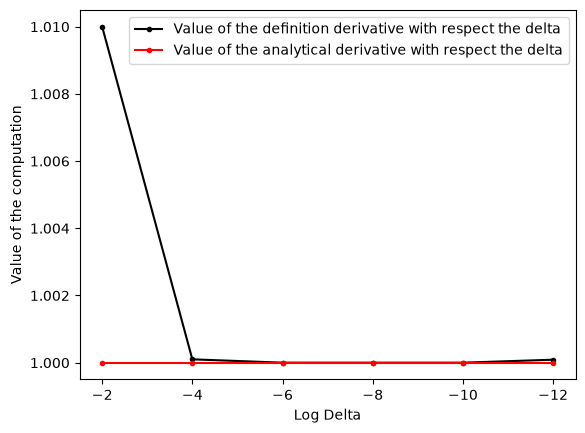

In [5]:
# (b) 
import matplotlib.pyplot as plt

exp = [2,4,6,8,10,12] # exponents of the delta
delta = [10**(-exps) for exps in exp]

errors = []
rs = []
qs = []

for i in range(len(exp)):
    r = df_definition(x1,delta[i])
    q = df_analytical(x1)
    error = np.abs((q-r)/r)
    errors.append(error)
    rs.append(r)
    qs.append(q)
    print(f'Result by definition at x = {x1} with delta = {delta[i]}: ',r, f'\nResult by analytically computing it at x = {x1}: ', q)
    print('Relative error between them: ', error , '\n')

plt.plot(np.log10(delta), rs, '.-', color = 'black', label = 'Value of the definition derivative with respect the delta')
plt.plot(np.log10(delta), qs, '.-', color = 'red', label = 'Value of the analytical derivative with respect the delta')
plt.xlabel('Log Delta')
plt.gca().invert_xaxis() 
plt.ylabel('Value of the computation')
plt.legend(loc = 'best')
plt.show()

## 7\. Consider the integral of the semicircle of radius 1:
$$
I=\int_{-1}^{1} \sqrt((1-x^2)) {\rm d}x
$$
which it's known to be $I=\frac{\pi}{2}=1.57079632679...$.
Alternatively we can use the Riemann definition of the integral:
$$
I=\lim_{N\to\infty} \sum_{k=1}^{N} h y_k 
$$

with $h=2/N$ the width of each of the $N$ slices the domain is divided into and where
$y_k$ is the value of the function at the $k-$th slice.

(a) Write a programe to compute the integral with $N=100$. How does the result compares to the true value?

(b) How much can $N$ be increased if the computation needs to be run in less than a second? What is the gain in running it for 1 minute? 


In [8]:
# (a) 

I_true = np.pi/2

N = 100
h = 2/N

def riemann_integral(N):
    h = 2.0 / (N - 1)
    x = np.linspace(-1, 1, N)
    y = np.sqrt(1 - x**2)
    I = np.sum(h * y)
    return I

print('Integral exactly computed: I_true =', I_true)
print('Integral computed with the Riemann summation: I_R =',riemann_integral(N))
print('Comparison between results: ', np.abs((I_true-riemann_integral(N))/I_true))

Integral exactly computed: I_true = 1.5707963267948966
Integral computed with the Riemann summation: I_R = 1.5691090196009048
Comparison between results:  0.0010741731217532382


In [20]:
# (b)
import time 
N_proves = 10000000
print("Beginning computation...")

#Doing the integral, this time will be timed 

time_begin = time.time()
result = riemann_integral(N_proves)
time_final = time.time()
delta_time = time_final - time_begin
error = abs(result- I_true)

print("-" * 50) #lines separation
print(f"N = {N_proves:,}")
print("-" * 50)
print(f"Computation time:   {delta_time:.4f} seconds")
print(f"Computed Value:        {result:.15f}")
print(f"True Value:      {I_true:.15f}")
print()
print(f"Absolut error: {error:.15e}")
print("-" * 50)

Beginning computation...
--------------------------------------------------
N = 10,000,000
--------------------------------------------------
Computation time:   0.1901 seconds
Computed Value:        1.570796326742305
True Value:      1.570796326794897

Absolut error: 5.259126467649367e-11
--------------------------------------------------
